<img src="https://raw.githubusercontent.com/carubbi/MQ/b58af070c45fb17b77640c06c0016859ad366b4d/notebooks/assets/imgs/UNIFOR_logo.png" width="400">
<br>
<b>
<font size="6" face="arial" color="blue">
    Graduação em Ciência da Computação
</font>
</b>
<br>
<b>
<font size="4" face="arial">
    Disciplina: Métodos Quantitativos em Computação
</font>
</b>

**Orientador: Prof. Me. Ricardo Carubbi** <br>
*Docente da Graduação e Pós-Graduação em Ciência de Dados e Inteligência Artificial*<br>
*Laboratório de Ciência de Dados e Inteligência Artificial*<br>
*Universidade de Fortaleza*<br>

# Semana 3 — Distribuições discretas: Binomial e Poisson

## 1. Objetivos de aprendizagem

Ao final da aula, o aluno será capaz de:

- definir o evento de sucesso e verificar as condições de um mecanismo Binomial.
- identificar parâmetros e valores possíveis de contagens Binomiais e de Poisson.
- calcular e interpretar probabilidades pontuais, acumuladas, esperanças e variâncias.
- comparar implementações por fórmula com resultados do SciPy e frequências simuladas.
- distinguir ensaios fixos de ocorrências em intervalo e avaliar a aproximação Binomial–Poisson.

## 2. Agenda

**Aula 5 — Binomial, 100 min**

1. Retomada discreta e Bernoulli — 20 min
2. Mecanismo e função de probabilidade Binomial — 25 min
3. Acumulada, esperança e variância — 20 min
4. Implementação sem biblioteca estatística — 15 min
5. Conferência com SciPy, simulação e gráficos — 10 min
6. Fechamento — 10 min

**Aula 6 — Poisson, 70 min no notebook**

1. Contagens em intervalos e parâmetro — 15 min
2. Probabilidades, acumulada e momentos (esperança e variância) — 15 min
3. Implementação sem biblioteca estatística — 12 min
4. Conferência com SciPy, simulação e gráficos — 8 min
5. Aproximação Binomial–Poisson — 15 min
6. Contraste dos mecanismos e fechamento — 5 min

Os 30 minutos finais da Aula 6 são reservados ao acompanhamento da AP2, fora deste notebook.

**Pergunta da aula:** 

> **Como identificar o evento de interesse e determinar se o número de suas ocorrências pode ser modelado por uma distribuição Binomial ou de Poisson?**


Na aula anterior, representamos resultados incertos por variáveis aleatórias e calculamos suas probabilidades, esperanças e variâncias. Nesta semana, identificaremos quando uma contagem pode ser modelada por uma distribuição binomial ou de Poisson, considerando o evento de interesse, a forma de contagem e as condições de aplicação de cada modelo.

## 3. Introdução

Em sistemas computacionais, podemos precisar estimar a probabilidade de pelo menos um e-mail ser spam em uma sequência de mensagens recebidas ou de um servidor receber mais requisições do que consegue atender em um intervalo. Para analisar esses problemas, precisamos definir a contagem de interesse e escolher um modelo probabilístico compatível com as condições de recebimento dos e-mails ou das requisições pelo servidor.

Seja $X$ o número de e-mails spam entre $n$ e-mails recebidos. Se os e-mails forem independentes e cada um tiver probabilidade $p$ de ser spam, então $X\sim\operatorname{Binomial}(n,p)$.

Seja $X$ o número de requisições recebidas pelo servidor em um intervalo de tempo. Se as requisições ocorrem com taxa média constante, as contagens em intervalos disjuntos são independentes e a probabilidade de duas ou mais requisições em um intervalo muito curto é desprezível, então $X\sim\operatorname{Poisson}(\lambda)$, sendo $\lambda$ o número médio de requisições no intervalo considerado (BARBETTA; REIS; BORNIA, 2010, pp. 127–129, 133–135; MONTGOMERY; RUNGER, 2018, pp. 52, 63–64).

Nas próximas seções, especificaremos o evento de interesse, as condições de cada modelo e os valores possíveis de cada contagem. Depois calcularemos suas probabilidades e conferiremos os resultados por código e simulação.

## 4. Ensaio de Bernoulli

O ponto de partida da Binomial é um **ensaio com dois resultados classificados previamente**. Na observação de e-mails, o **evento de interesse** é “o e-mail é spam”. Chamaremos sua ocorrência de **sucesso**, embora um e-mail spam seja indesejável na aplicação.

Outros exemplos de ensaios de Bernoulli:

- Ao lançar um dado, **sucesso** pode ser “sair seis” e **fracasso** pode ser “sair outra face”.
- Ao verificar um servidor em um instante definido, **sucesso** pode ser “estar ativo” e **fracasso** pode ser “estar inativo”.
- Ao testar uma conexão de rede, **sucesso** pode ser “conseguir estabelecer a conexão” e **fracasso** pode ser “não conseguir estabelecê-la”.

Em todos esses casos, as duas categorias são definidas antes da observação (BARBETTA; REIS; BORNIA, 2010, pp. 126–127).

Exemplos que não seguem o modelo de Bernoulli:

- Ao medir o tamanho de um e-mail em bytes, registramos uma medida que pode assumir diversos valores, em vez de indicar apenas a ocorrência ou não de um evento.
- Ao medir o tempo de resposta de um servidor, registramos uma duração que pode assumir diversos valores, em vez de indicar apenas a ocorrência ou não de um evento.

### 4.1 Variável de Bernoulli e função de probabilidade

Na observação de $n$ e-mails, seja $\Omega$ o **espaço amostral** das possíveis sequências de spam e não spam. Cada $\omega\in\Omega$ representa uma dessas sequências. Para o e-mail $i$, o evento de interesse reúne as sequências em que esse e-mail é spam. A variável de Bernoulli $X_i$ registra se o evento ocorreu (BARBETTA; REIS; BORNIA, 2010, p. 127):

$$
X_i(\omega)=\begin{cases}1,&\text{se o e-mail }i\text{ é spam em }\omega,\\0,&\text{caso contrário.}\end{cases}\qquad X_i(\Omega)=\{0,1\}.\tag{5.1}
$$

Se $p$ é a probabilidade de cada e-mail ser spam, então $\mathbb P(X_i=1)=p$ e $\mathbb P(X_i=0)=1-p$, com $0\leq p\leq1$. A **função de probabilidade**, ou seja, a função de massa de probabilidade (PMF, `pmf` nos pacotes), é

$$
f_{X_i}(x)=\mathbb P(X_i=x)=\begin{cases}1-p,&x=0,\\p,&x=1.\end{cases}\tag{5.2}
$$

O símbolo $x$ representa um dos **valores possíveis** de $X_i$: 0 (não spam) e 1 (spam). Se $p=0{,}10$, ambos têm probabilidade positiva e formam o **suporte** da distribuição: $\{0,1\}$. Se $p=0$, apenas 0 tem probabilidade positiva, embora a variável continue definida com valores em $\{0,1\}$. No SciPy, `bernoulli.support(p)` retorna os limites 0 e 1 mesmo quando um deles tem probabilidade zero. A soma das duas probabilidades é 1 (BARBETTA; REIS; BORNIA, 2010, p. 127; DEVLIN et al., 2018, pp. 31–35).

### 4.2 Esperança e variância

Como $X_i$ vale 1 com probabilidade $p$ e 0 com probabilidade $1-p$, sua **esperança**, ou seja, a média teórica da distribuição (`mean`), é a média ponderada desses valores. Nas somas abaixo, $x$ percorre os valores possíveis de $X_i$: 0 e 1. Sua **variância** (`var`), ou seja, a média teórica dos desvios quadráticos em relação à esperança, é calculada aqui em relação a $p$ (BARBETTA; REIS; BORNIA, 2010, p. 127; MONTGOMERY; RUNGER, 2018, p. 54):

$$
\mathbb E[X_i]=\sum_x x\,\mathbb P(X_i=x)=0(1-p)+1p=p.\tag{5.3}
$$

$$
\operatorname{Var}(X_i)=\sum_x\bigl(x-\mathbb E[X_i]\bigr)^2\,\mathbb P(X_i=x)=(0-p)^2(1-p)+(1-p)^2p=p(1-p).\tag{5.4}
$$

Embora cada resultado observado seja 0 ou 1, a esperança $p$ pode assumir qualquer valor entre esses extremos. A esperança tem a unidade de $X_i$ e a variância tem essa unidade ao quadrado (DEVLIN et al., 2018, pp. 10–13).

![Bernoulli com probabilidades de spam de 0,5 e 0,8 e respectivas esperanças](https://raw.githubusercontent.com/carubbi/MQ/main/notebooks/assets/imgs/u2_s03/bernoulli_esperanca.png)

**Figura 1 - Probabilidades e esperança de Bernoulli.** À esquerda, spam e não spam têm a mesma probabilidade. À direita, spam tem probabilidade 0,8. A linha tracejada marca a esperança, que pode estar entre 0 e 1, embora cada resultado observado seja um desses dois valores. Fonte: Adaptação de Navidi (2024, p. 201).

In [7]:
# Calcular esperança e variância de uma distribuição discreta pela definição
from math import isclose


def esp_discreta(valores: list[int], probs: list[float]) -> float:
    """Calcula a esperança pela soma dos valores ponderados pelas probabilidades."""
    
    if not valores or len(valores) != len(probs):
        raise ValueError('Use listas não vazias com o mesmo tamanho.')
    if any(q < 0 for q in probs) or not isclose(sum(probs), 1.0):
        raise ValueError('Use probabilidades não negativas cuja soma seja 1.')
    
    return sum(x * q for x, q in zip(valores, probs))


def var_discreta(valores: list[int], probs: list[float]) -> float:
    """Calcula a variância pela soma dos desvios quadráticos ponderados."""
    
    media = esp_discreta(valores, probs)
    
    return sum((x - media) ** 2 * q for x, q in zip(valores, probs))

In [8]:
# DECLARE O EVENTO DE INTERESSE E SUA PROBABILIDADE.
p_spam = 0.10
prob_b = {0: 1 - p_spam, 1: p_spam}
vals_b = list(prob_b)
m_b = esp_discreta(list(prob_b), list(prob_b.values()))
v_b = var_discreta(list(prob_b), list(prob_b.values()))

print("Sucesso: e-mail spam")
print("Valores possíveis:", vals_b)
print("Esperança de X_i (Bernoulli):", m_b)
print("Variância de X_i (Bernoulli):", v_b)

Sucesso: e-mail spam
Valores possíveis: [0, 1]
Esperança de X_i (Bernoulli): 0.1
Variância de X_i (Bernoulli): 0.09000000000000002


In [ ]:
# Comparar com os resultados finais das equações 5.3 e 5.4 para Bernoulli
v_bern = p_spam * (1 - p_spam)

print("Esperança de X_i (Bernoulli, p):", p_spam)
print("Variância de X_i (Bernoulli, p * (1 - p)):", v_bern)

Esperança de X_i (Bernoulli, p): 0.1
Variância de X_i (Bernoulli, p * (1 - p)): 0.09000000000000001


A esperança de $0{,}10$ da variável de Bernoulli $X_i$ corresponde a uma proporção teórica de 10% de e-mails spam sob o modelo. A variância de $0{,}09$ descreve o desvio quadrático médio da variável de Bernoulli $X_i$.

## 5. Distribuição Binomial

Em cada **ensaio de Bernoulli**, a variável $X_i$ registra se o evento de interesse ocorreu. A variável Binomial $X$ conta **em quantos ensaios esse evento ocorreu**.

Exemplos de contagens que podem seguir uma distribuição Binomial, se os ensaios forem **independentes** e tiverem a **mesma probabilidade de sucesso**:

- Ao lançar uma moeda justa cinco vezes, contar **quantas caras** são obtidas.
- Ao inspecionar dez itens produzidos, contar **quantos apresentam defeito**, sob probabilidade de defeito constante para cada item.
- Ao observar 20 e-mails recebidos, contar **quantos são spam**, sob probabilidade de spam constante para cada e-mail.

Em cada exemplo, o número de ensaios é fixado antes da observação (BARBETTA; REIS; BORNIA, 2010, pp. 127–128).

Exemplos que não atendem às condições do modelo binomial:

- Ao observar os e-mails até encontrar o primeiro spam, o número de ensaios depende dos resultados observados, em vez de ser fixado previamente.
- Ao contar os e-mails spam entre 20 mensagens com probabilidades diferentes de serem spam, a probabilidade de sucesso não é constante entre os ensaios.

### 5.1 Condições do modelo binomial e variável aleatória

Para modelar por uma distribuição Binomial o número de ocorrências de um **evento de interesse**, verifique as condições:

- **Número fixo de ensaios:** são realizados $n$ ensaios, com $n$ inteiro positivo definido antes da observação.
- **Dois resultados por ensaio:** o evento de interesse ocorre ou não ocorre. A variável $X_i$ vale 1 no primeiro caso e 0 no segundo.
- **Independência:** o resultado de um ensaio não altera a probabilidade dos resultados dos demais.
- **Probabilidade constante:** $\mathbb P(X_i=1)=p$ para todo $i$, com $0\leq p\leq1$ (BARBETTA; REIS; BORNIA, 2010, pp. 127–128; MONTGOMERY; RUNGER, 2018, pp. 51–52).

Na observação de $n$ e-mails, o evento de interesse é “o e-mail é spam”. Para cada resultado $\omega$ da sequência completa de e-mails, a variável $X$ conta os e-mails spam:

$$
X(\omega)=\sum_{i=1}^{n}X_i(\omega),\qquad X(\Omega)=\{0,1,\ldots,n\}.\tag{5.5}
$$

Quando as condições acima valem, escrevemos $X\sim\operatorname{Binomial}(n,p)$ (BARBETTA; REIS; BORNIA, 2010, pp. 127–128; MONTGOMERY; RUNGER, 2018, pp. 51–52). 

Se $p=0$ ou $p=1$, somente um valor de $X$ tem probabilidade positiva. Para $0<p<1$, sucesso e fracasso são possíveis em cada ensaio. 

Em retiradas sem reposição, cada resultado altera a composição da população. Assim, a probabilidade de sucesso na retirada seguinte pode depender do resultado anterior, contrariando a independência e a constância de $p$ exigidas pelo modelo Binomial (BARBETTA; REIS; BORNIA, 2010, p. 132).

### 5.2 Função de probabilidade

Para contar de quantas formas $k$ dos $n$ ensaios podem resultar em sucesso (neste exemplo, $k$ dos $n$ e-mails serem spam), usamos o **coeficiente binomial**.

$$
\binom nk=\frac{n!}{k!(n-k)!},\qquad 0\leq k\leq n,
$$

em que $n!$ é o fatorial de $n$ e $0!=1$. O coeficiente conta as maneiras de escolher os $k$ ensaios que resultam em sucesso, sem considerar a ordem da escolha. Neste exemplo, são as posições dos $k$ e-mails spam. Em quatro e-mails, $\binom42=6$ escolhas de posições correspondem a exatamente dois e-mails spam (BARBETTA; REIS; BORNIA, 2010, pp. 129–130).

In [9]:
# DEMONSTRE AS SEQUÊNCIAS COM EXATAMENTE DOIS E-MAILS SPAM ENTRE QUATRO E-MAILS.
from itertools import combinations

posicoes = list(combinations(range(4), 2))
seqs = []
for pos in posicoes:
    seq = ["S" if i in pos else "N" for i in range(4)]
    seqs.append(" ".join(seq))
n_comb = len(posicoes)

print("S = spam; N = não spam")
for seq in seqs:
    print(seq)
print("Quantidade de combinações de posições:", n_comb)

S = spam; N = não spam
S S N N
S N S N
S N N S
N S S N
N S N S
N N S S
Quantidade de combinações de posições: 6


Pela independência dos ensaios, multiplicamos as probabilidades dos resultados individuais. Por exemplo, a sequência **S S N N** tem probabilidade:

$$
p\cdot p\cdot(1-p)\cdot(1-p)=p^2(1-p)^2.
$$

Portanto, cada sequência com $k$ sucessos e $n-k$ fracassos tem probabilidade $p^k(1-p)^{n-k}$. Como existem $\binom nk$ dessas sequências, a **função de probabilidade binomial** é

$$
f_X(k)=\mathbb P(X=k)=\binom nk p^k(1-p)^{n-k},\qquad k=0,1,\ldots,n.\tag{5.6}
$$

Aqui $X$ conta os sucessos em $n$ ensaios, $k$ é um valor possível dessa contagem e $p$ é a probabilidade de sucesso em cada ensaio. Neste exemplo, sucesso é o e-mail ser spam. A fórmula pressupõe as condições descritas na seção 5.1 (BARBETTA; REIS; BORNIA, 2010, pp. 129–130; MONTGOMERY; RUNGER, 2018, pp. 52–53; DEVLIN et al., 2018, pp. 34–35).

As seis sequências correspondem ao coeficiente binomial para $n=4$ (quatro e-mails observados, cada um constituindo um ensaio de Bernoulli) e $k=2$ (dois e-mails spam). Todas têm a mesma probabilidade sob independência e $p$ constante.

![As 16 sequências de quatro e-mails agrupadas pelo número de mensagens spam](https://raw.githubusercontent.com/carubbi/MQ/main/notebooks/assets/imgs/u2_s03/binomial_sequencias.png)

**Figura 2 - Das sequências à contagem binomial.** Os 16 resultados possíveis de quatro ensaios são agrupados pelo número de e-mails spam. As quantidades 1, 4, 6, 4 e 1 correspondem aos coeficientes binomiais. A probabilidade de cada contagem é a soma das probabilidades das sequências do grupo, sob independência e probabilidade de spam constante. Fonte: Adaptação de Barbetta, Reis e Bornia (2010, p. 128).

### 5.3 Função de distribuição acumulada

A acumulada, ou seja, a função de distribuição acumulada (CDF, `cdf`), representada por $F_X(k)$, fornece a probabilidade do evento $\{X\leq k\}$, isto é, de haver no máximo $k$ e-mails spam:

$$
F_X(k)=\mathbb P(X\leq k)=\sum_{j=0}^{k}f_X(j),\quad
\mathbb P(X>k)=1-F_X(k),\quad
\mathbb P(X\geq k)=1-F_X(k-1).\tag{5.7}
$$

A cauda superior, ou seja, a probabilidade de superar $k$, é $\mathbb P(X>k)=1-F_X(k)$ e pode ser calculada pela função de sobrevivência (`sf`).

O índice $j$ percorre as contagens incluídas na soma. “Mais de $k$” exclui $k$. “Pelo menos $k$” o inclui. Para $k=0$, convencionamos $F_X(-1)=0$ (MONTGOMERY; RUNGER, 2018, seção 3.2, pp. 45–46).

![Probabilidades individuais e função acumulada para quatro e-mails](https://raw.githubusercontent.com/carubbi/MQ/main/notebooks/assets/imgs/u2_s03/binomial_acumulada.png)

**Figura 3 - Probabilidades e função de distribuição acumulada.** À esquerda, cada barra representa a probabilidade de uma contagem de spam entre quatro e-mails independentes, com $p=0{,}10$. À direita, a acumulada soma essas probabilidades até o valor indicado. Por exemplo, $F(2)=0{,}6561+0{,}2916+0{,}0486=0{,}9963$. Os círculos preenchidos indicam o valor da função em cada ponto. Fonte: Adaptação de Montgomery e Runger (2018, pp. 45–46).

### 5.4 Esperança e variância

A esperança da variável binomial $X$ soma as esperanças das $n$ variáveis de Bernoulli $X_i$. Como essas variáveis são independentes, suas variâncias também se somam (BARBETTA; REIS; BORNIA, 2010, pp. 130–131; MONTGOMERY; RUNGER, 2018, p. 54):

$$
\mathbb E[X]=np.\tag{5.8}
$$

$$
\operatorname{Var}(X)=np(1-p).\tag{5.9}
$$

O valor $np$ é a média teórica de muitas contagens, não necessariamente um número inteiro possível em uma sequência de e-mails. A esperança tem a unidade da contagem e a variância tem essa unidade ao quadrado. Elas são propriedades do modelo e não recebem correção amostral por $n-1$ (DEVLIN et al., 2018, pp. 10–13).

### 5.5 Implementação Manual

Considere $n=20$ e-mails e $p=0{,}10$ de cada e-mail ser spam. A função `math.comb` da biblioteca padrão do Python calcula $\binom nk$. O código aplica a Equação (5.6) diretamente, sem pacote estatístico. Depois, somamos as massas de probabilidade, isto é, as probabilidades de cada valor possível, para obter probabilidades acumuladas. A esperança e a variância são calculadas por somas ponderadas.

In [10]:
# Calcular a probabilidade binomial pela definição
from math import comb


def prob_binom(k: int, n: int, p: float) -> float:
    """Calcula a probabilidade de exatamente k sucessos em n ensaios."""
    
    if n < 1 or not 0 <= k <= n:
        raise ValueError('Use n positivo e k entre 0 e n.')
    if not 0 <= p <= 1:
        raise ValueError('Use uma probabilidade p entre 0 e 1.')
    
    return comb(n, k) * p**k * (1 - p)**(n - k)

In [11]:
# Aplicar a função à contagem de e-mails spam
n = 20
p = 0.10
p_x2 = prob_binom(2, n, p)
p_x_max2 = prob_binom(0, n, p) + prob_binom(1, n, p) + prob_binom(2, n, p)
p_x_maior2 = 1 - (prob_binom(0, n, p) + prob_binom(1, n, p) + prob_binom(2, n, p))

print("P(X = 2):", p_x2)
print("P(X ≤ 2):", p_x_max2)
print("P(X > 2):", p_x_maior2)

P(X = 2): 0.2851798070642985
P(X ≤ 2): 0.6769268051894664
P(X > 2): 0.32307319481053365


O complemento de $X\leq2$ é $X>2$. Já o evento $X\geq2$ inclui o resultado de dois e-mails spam.

In [ ]:
# VERIFIQUE A MASSA TOTAL E A NÃO NEGATIVIDADE.
vals_x = list(range(n + 1)) # 0,1,...,n
prob_x = []
for k in vals_x:
    prob_x.append(prob_binom(k, n, p))  # [0.12, 0.27, 0.29, ..., 1e-20].

probs_nao_neg = sum(q < 0 for q in prob_x) == 0
soma_prob = sum(prob_x)

print("Massas não negativas:", probs_nao_neg)
print("Soma das massas:", soma_prob)

Massas não negativas: True
Soma das massas: 1.0000000000000007


In [14]:
# Alternativa ao laço: construir as probabilidades por compreensão de lista
prob_x = [prob_binom(k, n, p) for k in vals_x]
p_x2 = prob_x[2]
p_x_max2 = sum(prob_x[:3])
p_x_maior2 = 1 - sum(prob_x[:3])

print("P(X = 2):", p_x2)
print("P(X ≤ 2):", p_x_max2)
print("P(X > 2):", p_x_maior2)

P(X = 2): 0.2851798070642985
P(X ≤ 2): 0.6769268051894665
P(X > 2): 0.32307319481053354


As probabilidades calculadas são não negativas e somam 1. Essa verificação é necessária para interpretar a lista como uma função de probabilidade (BARBETTA; REIS; BORNIA, 2010, p. 126; MONTGOMERY; RUNGER, 2018, seção 3.1, p. 44).

In [15]:
# Aplicar as funções de esperança e variância à distribuição binomial
m_x = esp_discreta(vals_x, prob_x)
v_x = var_discreta(vals_x, prob_x)

print("Esperança de X (binomial, cálculo manual):", m_x, "e-mails spam")
print("Variância de X (binomial, cálculo manual):", v_x, "(e-mail spam)^2")

Esperança de X (binomial, cálculo manual): 2.0000000000000013 e-mails spam
Variância de X (binomial, cálculo manual): 1.8000000000000012 (e-mail spam)^2


Em muitas sequências de 20 e-mails, a contagem média teórica é **2 e-mails spam**. A média teórica dos desvios quadráticos em relação a 2 é **1,8 (e-mail spam)^2**.

### 5.6 Conferência com Biblioteca e simulação

O SciPy oferece `pmf`, `cdf`, `mean`, `var` e `rvs` para conferir a implementação. A simulação, neste caso, é a geração de uma amostra aleatória da distribuição (`rvs`). Ela produz uma amostra finita, cujas frequências podem variar entre amostras (SCIPY COMMUNITY, s. d.).

A frequência relativa simulada, ou seja, a proporção de ocorrências de cada valor na amostra gerada, será usada na comparação com as massas de probabilidade.

In [16]:
# CONFIRA OS CÁLCULOS COM A BIBLIOTECA.
from scipy.stats import binom

p_x2_lib = binom.pmf(2, n, p)
p_x_max2_lib = binom.cdf(2, n, p)
m_lib_x = binom.mean(n, p)
v_lib_x = binom.var(n, p)
dif_max = max(abs(q - binom.pmf(k, n, p)) for k, q in zip(vals_x, prob_x))

print("P(X = 2):", p_x2_lib)
print("P(X ≤ 2):", p_x_max2_lib)
print("Esperança de X (binomial, SciPy):", m_lib_x, "e-mails spam")
print("Variância de X (binomial, SciPy):", v_lib_x, "(e-mail spam)^2")
print("Maior diferença nas massas:", dif_max)

P(X = 2): 0.2851798070642987
P(X ≤ 2): 0.6769268051894659
Esperança de X (binomial, SciPy): 2.0 e-mails spam
Variância de X (binomial, SciPy): 1.8 (e-mail spam)^2
Maior diferença nas massas: 1.6653345369377348e-16


A implementação pela fórmula e os métodos da biblioteca concordam até o arredondamento numérico. A próxima amostra é uma realização do mesmo modelo.

In [ ]:
# SIMULE MIL SEQUÊNCIAS DE 20 E-MAILS COM SEMENTE FIXA.
import numpy as np

seed = 2026

sim_x = binom.rvs(n, p, size=1000, random_state=seed)
freq_x = np.bincount(sim_x, minlength=n + 1) / sim_x.size
m_sim_x = np.mean(sim_x)
v_sim_x = np.var(sim_x)

print("Média simulada de X (binomial):", m_sim_x)
print("Variância simulada de X (binomial):", v_sim_x)

Média simulada de X (binomial): 2.038
Variância simulada de X (binomial): 1.7745559999999998


A média simulada, ou seja, a média da amostra gerada (`np.mean`), não precisa ser exatamente 2. A variância simulada, ou seja, a variância da amostra gerada (`np.var`, com `ddof=0`), também pode diferir do valor teórico de 1,8. A semente fixa reproduz esta amostra. Outra semente produz outra realização sob os mesmos parâmetros.

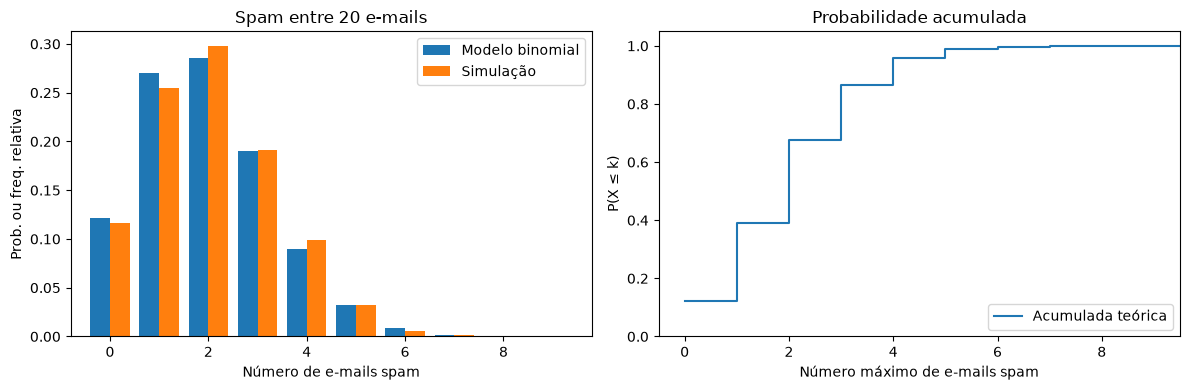

In [ ]:
# COMPARE MASSAS TEÓRICAS, FREQUÊNCIAS E ACUMULADA.
import matplotlib.pyplot as plt

fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
eixos[0].bar(np.array(vals_x) - 0.2, prob_x, width=0.4, label="Modelo binomial")
eixos[0].bar(np.array(vals_x) + 0.2, freq_x, width=0.4, label="Simulação")
eixos[0].set(xlabel="Número de e-mails spam", ylabel="Prob. ou freq. relativa", title="Spam entre 20 e-mails", xlim=(-0.8, 9.8))
eixos[0].legend()
eixos[1].step(vals_x, np.cumsum(prob_x), where="post", label="Acumulada teórica")
eixos[1].set(xlabel="Número máximo de e-mails spam", ylabel="P(X ≤ k)", title="Probabilidade acumulada", xlim=(-0.5, 9.5), ylim=(0, 1.05))
eixos[1].legend(loc="lower right")
fig.tight_layout()
plt.show()

**Figura 4 - Massa Binomial, simulação e acumulada.** À esquerda, dois e-mails spam estão entre as contagens mais prováveis no modelo de 20 e-mails com $p=0{,}10$, e as frequências simuladas ficam próximas das massas teóricas. À direita, cada degrau acumula as massas até o número de e-mails spam indicado. Fonte: Elaboração própria, inspirada em Seeing Theory (s. d.).

## 6. Distribuição de Poisson

Agora, o evento de interesse é o recebimento de uma requisição pelo servidor. Fixamos uma **janela de tempo** e contamos quantas vezes esse evento ocorre. O número de requisições recebidas não foi fixado antes da observação.

Exemplos de contagens que podem seguir uma distribuição de Poisson, sob as condições apresentadas na seção 6.1:

- Ao monitorar um servidor, contar **quantas requisições são recebidas em um minuto**.
- Ao acompanhar um equipamento, contar **quantas falhas ocorrem em uma semana**.

Exemplos que podem contrariar as condições do modelo de Poisson apresentado:

- Ao contar requisições em que o recebimento de uma desencadeia outras, as ocorrências podem ser dependentes.
- Ao contar requisições durante um período em que a taxa de recebimento varia, a condição de taxa constante pode não ser atendida.

### 6.1 Condições do modelo de Poisson

Seja $\Omega$ o **espaço amostral** dos possíveis resultados da observação de ocorrências de um evento em um intervalo de tempo. A variável $Y_t:\Omega\longrightarrow\{0,1,2,\ldots\}$ associa a cada resultado $\omega$ o número de ocorrências nesse intervalo. No exemplo do servidor, $\omega$ representa um possível registro dos horários de recebimento das requisições, e $Y_t(\omega)$ conta quantas foram recebidas nos $t$ minutos. 

Um processo de Poisson homogêneo pressupõe independência entre intervalos disjuntos, taxa estável e chance desprezível de duas ocorrências em um intervalo muito curto (BARBETTA; REIS; BORNIA, 2010, pp. 133–134; MONTGOMERY; RUNGER, 2018, p. 63).

Se $r$ é a taxa média de ocorrências por unidade de tempo (neste exemplo, requisições recebidas por minuto), a média no intervalo é

$$
\lambda=rt,\qquad Y_t\sim\operatorname{Poisson}(\lambda),\qquad \lambda>0.\tag{6.1}
$$

Nesta notação, $r$ representa a taxa e $\lambda$ a média no intervalo.

No exemplo, a taxa $r$ tem unidade requisições recebidas/minuto. O intervalo $t$ tem unidade minuto. O parâmetro $\lambda$ é o número médio esperado de requisições recebidas **nessa janela**. Para $r=3$, temos $\lambda=3$ em um minuto e $\lambda=1{,}5$ em 30 segundos. A constância de uma média observada não comprova as demais hipóteses (BARBETTA; REIS; BORNIA, 2010, pp. 134–135; MONTGOMERY; RUNGER, 2018, pp. 63–64).

In [ ]:
# CONVERTA A TAXA PARA AS DUAS JANELAS DE OBSERVAÇÃO.
r = 3.0  # requisições recebidas por minuto
lam_1m = r * 1.0
lam_30s = r * 0.5

print("Média em um minuto:", lam_1m, "requisições recebidas")
print("Média em 30 segundos:", lam_30s, "requisições recebidas")

Média em um minuto: 3.0 requisições recebidas
Média em 30 segundos: 1.5 requisições recebidas


Ao reduzir a janela pela metade, a média esperada passa de 3 para 1,5 requisições recebidas. Empregar $\lambda=3$ para 30 segundos representaria outra taxa.

### 6.2 Função de probabilidade e acumulada

Para uma janela fixa de $t$ minutos, escreva $Y=Y_t$ e $\lambda=rt$. Se $Y\sim\operatorname{Poisson}(\lambda)$, a probabilidade de exatamente $k$ requisições recebidas é

$$
f_Y(k)=\mathbb P(Y=k)=e^{-\lambda}\frac{\lambda^k}{k!},\qquad k\in\{0,1,2,\ldots\}.\tag{6.2}
$$

Nessa expressão, $e\approx2{,}71828$ é o número de Euler, base da função exponencial natural.

Para obter a Equação (6.2), dividimos o intervalo em $n$ subintervalos suficientemente pequenos. Sob as condições do processo de Poisson, cada subintervalo pode ser aproximado por um ensaio de Bernoulli com probabilidade $p=\lambda/n$ de ocorrência.


![Três requisições em um minuto e o mesmo registro dividido em subintervalos](https://raw.githubusercontent.com/carubbi/MQ/main/notebooks/assets/imgs/u2_s03/poisson_intervalos_160.png)

**Figura 5 - Requisições em um intervalo de tempo.** Cada cruz representa uma requisição recebida. O registro ilustrativo contém três requisições em um minuto. A divisão em subintervalos suficientemente pequenos, de duração $\Delta t$ mantém todas as ocorrências e ajuda a interpretar a hipótese sobre múltiplas requisições em intervalos muito curtos. O desenho, isoladamente, não demonstra que o processo satisfaz as condições de Poisson. Fonte: Adaptação de Barbetta, Reis e Bornia (2010, p. 134).

A contagem total é, então, aproximada por uma binomial:

$$
\mathbb P(Y=k)\approx\binom nk\left(\frac{\lambda}{n}\right)^k\left(1-\frac{\lambda}{n}\right)^{n-k}.
$$

Reorganizando a expressão, para $k$ fixo:

$$
\mathbb P(Y=k)\approx\frac{\lambda^k}{k!}
\underbrace{\frac{n(n-1)\cdots(n-k+1)}{n^k}}_{\longrightarrow\,1}
\underbrace{\left(1-\frac{\lambda}{n}\right)^n}_{\longrightarrow\,e^{-\lambda}}
\underbrace{\left(1-\frac{\lambda}{n}\right)^{-k}}_{\longrightarrow\,1}.
$$

Tomando o limite quando $n\to\infty$, obtemos a Equação (6.2) (BARBETTA; REIS; BORNIA, 2010, pp. 134–135; MONTGOMERY; RUNGER, 2018, p. 63):

$$
\mathbb P(Y=k)=e^{-\lambda}\frac{\lambda^k}{k!},\qquad k=0,1,2,\ldots.
$$

O valor $k=0$ está incluído: $f_Y(0)=e^{-\lambda}$ (BARBETTA; REIS; BORNIA, 2010, p. 135; MONTGOMERY; RUNGER, 2018, p. 63). Aqui $\lambda$ é a média na janela e $k!$ é o fatorial de $k$. A função acumulada fornece a probabilidade de ocorrerem no máximo $k$ requisições recebidas:

$$
F_Y(k)=\mathbb P(Y\leq k)=\sum_{j=0}^{k}f_Y(j),\qquad
\mathbb P(Y>k)=1-F_Y(k).\tag{6.3}
$$

O índice $j$ percorre as contagens incluídas. O complemento representa mais de $k$ requisições recebidas, não pelo menos $k$ (BARBETTA; REIS; BORNIA, 2010, p. 135; MONTGOMERY; RUNGER, 2018, seção 3.2, pp. 45–46).

![Probabilidades e função acumulada de Poisson com média de três requisições por minuto](https://raw.githubusercontent.com/carubbi/MQ/main/notebooks/assets/imgs/u2_s03/poisson_prob_acumulada.png)

**Figura 6 - Probabilidades e função de distribuição acumulada de Poisson.** À esquerda, cada barra representa a probabilidade de uma quantidade de requisições recebidas em um minuto, com $\lambda=3$. À direita, a altura da acumulada em $k=2$ é $P(Y\leq2)\approx0{,}4232$, soma das probabilidades de zero, uma e duas requisições. Os marcadores preenchidos indicam os valores da função. O gráfico exibe contagens até 12, mas o modelo admite valores superiores. Fonte: Adaptação de Barbetta, Reis e Bornia (2010, p. 135) e Montgomery e Runger (2018, pp. 46, 64).

### 6.3 Esperança e variância

No modelo de Poisson, as duas propriedades têm o mesmo valor numérico (BARBETTA; REIS; BORNIA, 2010, p. 135; MONTGOMERY; RUNGER, 2018, p. 65):

$$
\mathbb E[Y]=\lambda.\tag{6.4}
$$

Pela definição de esperança e pela função de probabilidade da Equação (6.2):

$$
\mathbb E[Y]=\sum_{k=0}^{\infty}k\,\mathbb P(Y=k)=\sum_{k=0}^{\infty}k\,e^{-\lambda}\frac{\lambda^k}{k!}
=\lambda\sum_{k=1}^{\infty}e^{-\lambda}\frac{\lambda^{k-1}}{(k-1)!}.
$$

O termo com $k=0$ é nulo. Substituindo $j=k-1$, a soma restante reúne todas as probabilidades de uma distribuição de Poisson e vale 1:

$$
\sum_{j=0}^{\infty}e^{-\lambda}\frac{\lambda^j}{j!}=1.
$$

Portanto, obtemos a Equação (6.4):

$$
\mathbb E[Y]=\lambda\cdot1=\lambda.
$$

$$
\operatorname{Var}(Y)=\lambda.\tag{6.5}
$$

Para demonstrar a Equação (6.5), calculamos primeiro $\mathbb E[Y(Y-1)]$. Os termos com $k=0$ e $k=1$ são nulos:

$$
\mathbb E[Y(Y-1)]
=\sum_{k=2}^{\infty}k(k-1)e^{-\lambda}\frac{\lambda^k}{k!}
=\lambda^2\sum_{k=2}^{\infty}e^{-\lambda}\frac{\lambda^{k-2}}{(k-2)!}.
$$

Substituindo $j=k-2$, a soma restante também vale 1:

$$
\mathbb E[Y(Y-1)]
=\lambda^2\sum_{j=0}^{\infty}e^{-\lambda}\frac{\lambda^j}{j!}
=\lambda^2.
$$

Como $Y^2=Y(Y-1)+Y$, temos:

$$
\mathbb E[Y^2]=\mathbb E[Y(Y-1)]+\mathbb E[Y]=\lambda^2+\lambda.
$$

Aplicando a definição de variância, obtemos a Equação (6.5):

$$
\operatorname{Var}(Y)
=\mathbb E[Y^2]-(\mathbb E[Y])^2
=(\lambda^2+\lambda)-\lambda^2
=\lambda.
$$

A esperança usa a unidade da contagem e a variância usa essa unidade ao quadrado. Para $\lambda=3$, são 3 requisições recebidas e 3 requisições recebidas^2, respectivamente. Em dados observados, variância muito maior que a média sugere inadequação do modelo. Valores próximos não provam ajuste (MONTGOMERY; RUNGER, 2018, p. 65).

### 6.4 Implementação Manual

O parâmetro $\lambda$ corresponde ao argumento `mu` de `scipy.stats.poisson` e ao argumento `lam` da função implementada abaixo.

Fixe $t=1$ minuto, de modo que $Y=Y_1$ e $\lambda=3$. Calcule as probabilidades de $Y=k$ com `math.exp` e `math.factorial`, da biblioteca padrão. Como Poisson permite contagens arbitrariamente altas, uma soma interrompida em um valor deixa uma cauda fora da tabela.

In [ ]:
# Calcular a probabilidade de Poisson pela definição
from math import exp, factorial


def prob_poisson(k: int, lam: float) -> float:
    """Calcula a probabilidade de exatamente k ocorrências com média lam."""
    if k < 0:
        raise ValueError('Use uma contagem k não negativa.')
    if lam <= 0:
        raise ValueError('Use uma média lam positiva.')
    return exp(-lam) * lam**k / factorial(k)

In [ ]:
# CALCULE MASSAS E ACUMULADA EM UM MINUTO.
vals_y = list(range(13))
prob_y = [prob_poisson(k, lam_1m) for k in vals_y]
p_y0 = round(prob_y[0], 6)
p_y2 = round(prob_y[2], 6)
p_y_max2 = round(sum(prob_y[:3]), 6)
p_y_maior12 = round(1 - sum(prob_y), 6)

print("P(Y = 0):", p_y0)
print("P(Y = 2):", p_y2)
print("P(Y ≤ 2):", p_y_max2)
print("P(Y > 12):", p_y_maior12)

P(Y = 0): 0.049787
P(Y = 2): 0.224042
P(Y ≤ 2): 0.42319
P(Y > 12): 1.6e-05


A probabilidade acima de 12 requisições recebidas é pequena, mas positiva. A soma truncada até 12 não é a massa total do modelo.

### 6.5 Conferência com Biblioteca, simulação e gráfico

Compare os cálculos com `scipy.stats.poisson`. Uma nova amostra de 1.000 minutos ilustra a variabilidade da simulação. A massa além do último valor visível continua pertencendo ao modelo (SCIPY COMMUNITY, s. d.).

In [ ]:
# CONFIRA A FUNÇÃO MASSA, A ACUMULADA E OS MOMENTOS (ESPERANÇA E VARIÂNCIA).
from scipy.stats import poisson

p_y2_lib = round(poisson.pmf(2, lam_1m), 6)
p_y_max2_lib = round(poisson.cdf(2, lam_1m), 6)
m_lib_y = poisson.mean(lam_1m)
v_lib_y = poisson.var(lam_1m)

print("P(Y = 2):", p_y2_lib)
print("P(Y ≤ 2):", p_y_max2_lib)
print("Esperança de Y (Poisson, SciPy):", m_lib_y, "requisições recebidas")
print("Variância de Y (Poisson, SciPy):", v_lib_y, "requisições recebidas^2")

P(Y = 2): 0.224042
P(Y ≤ 2): 0.42319
Esperança de Y (Poisson, SciPy): 3.0 requisições recebidas
Variância de Y (Poisson, SciPy): 3.0 requisições recebidas^2


In [ ]:
# SIMULE MIL MINUTOS COM SEMENTE FIXA.
sim_y = poisson.rvs(lam_1m, size=1000, random_state=seed)
freq_y = [sum(sim_y == k) / len(sim_y) for k in vals_y]
m_sim_y = round(float(np.mean(sim_y)), 4)
v_sim_y = round(float(np.var(sim_y)), 4)
p_y_maior12_lib = round(poisson.sf(12, lam_1m), 6)

print("Média simulada de Y (Poisson):", m_sim_y, "requisições recebidas")
print("Variância simulada de Y (Poisson):", v_sim_y, "requisições recebidas^2")
print("Probabilidade de cauda superior P(Y > 12):", p_y_maior12_lib)

Média simulada de Y (Poisson): 3.096 requisições recebidas
Variância simulada de Y (Poisson): 3.0788 requisições recebidas^2
Probabilidade de cauda superior P(Y > 12): 1.6e-05


A média e a variância da amostra são valores observados em 1.000 minutos simulados. Podem diferir dos valores teóricos $\lambda=3$. A probabilidade acima de 12 requisições recebidas explica por que o gráfico não mostra toda a massa.

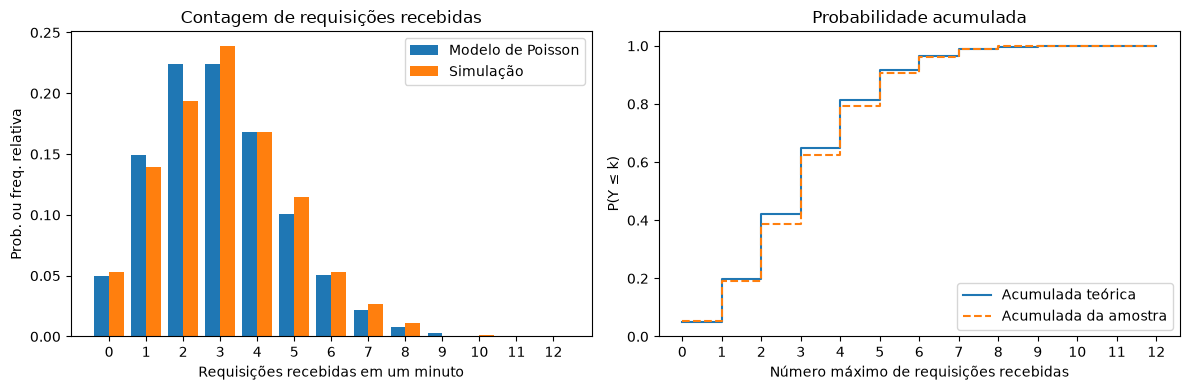

In [ ]:
# Comparar probabilidades, frequências relativas e acumuladas
acum_y = poisson.cdf(vals_y, lam_1m)
acum_sim_y = np.cumsum(freq_y)

fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
eixos[0].bar(np.array(vals_y) - 0.2, prob_y, width=0.4, label="Modelo de Poisson")
eixos[0].bar(np.array(vals_y) + 0.2, freq_y, width=0.4, label="Simulação")
eixos[0].set(xlabel="Requisições recebidas em um minuto", ylabel="Prob. ou freq. relativa", title="Contagem de requisições recebidas", xticks=vals_y)
eixos[0].legend()
eixos[1].step(vals_y, acum_y, where="post", label="Acumulada teórica")
eixos[1].step(vals_y, acum_sim_y, where="post", linestyle="--", label="Acumulada da amostra")
eixos[1].set(xlabel="Número máximo de requisições recebidas", ylabel="P(Y ≤ k)", title="Probabilidade acumulada", xticks=vals_y, ylim=(0, 1.05))
eixos[1].legend(loc="lower right")
fig.tight_layout()
plt.show()

**Figura 7 - Probabilidades, simulação e acumuladas de Poisson.** À esquerda, as frequências relativas simuladas são comparadas às probabilidades teóricas de $\operatorname{Poisson}(3)$, cujas maiores massas ocorrem em duas e três requisições. À direita, a acumulada da amostra é comparada à acumulada teórica. Os gráficos mostram contagens até 12, mas o modelo admite valores superiores. Fonte: Elaboração própria, inspirada em Seeing Theory (s. d.).

## 7. Aproximação Binomial–Poisson

Nesta seção, $X$ é o número de sucessos em $n$ ensaios independentes, cada um com probabilidade $p$ de sucesso. $Y$ é uma contagem de Poisson usada para aproximar $X$. A demonstração da seção 6.2, apoiada pela Figura 5, fundamenta essa aproximação.

Para $n$ grande e $p$ pequeno, adotamos $\lambda=np$ e usamos a aproximação (BARBETTA; REIS; BORNIA, 2010; MONTGOMERY; RUNGER, 2018):

$$
X\sim\operatorname{Binomial}(n,p),\quad Y\sim\operatorname{Poisson}(np),\quad
\mathbb P(X>k)\approx\mathbb P(Y>k).\tag{6.6}
$$

No exemplo, $n=500$, $p=0{,}005$ e $\lambda=2{,}5$. Comparamos a probabilidade de mais de quatro sucessos nos dois modelos. Não existe um limiar universal de $n$ e $p$ que garanta a mesma precisão em todos os eventos. A Binomial exata permite avaliar o erro neste caso.

In [32]:
# CALCULE A CAUDA BINOMIAL EXATA E A APROXIMAÇÃO PELAS FÓRMULAS.
n = 500
p = 0.005
lam = n * p
bin_max4 = sum(prob_binom(k, n, p) for k in range(5))
poi_max4 = sum(prob_poisson(k, lam) for k in range(5))
bin_maior4 = 1 - bin_max4
poi_maior4 = 1 - poi_max4
dif_abs = round(abs(bin_maior4 - poi_maior4), 6)

print("Binomial exata P(X > 4):", round(bin_maior4, 6))
print("Poisson aproximada P(Y > 4):", round(poi_maior4, 6))
print("Diferença absoluta:", dif_abs)

Binomial exata P(X > 4): 0.108319
Poisson aproximada P(Y > 4): 0.108822
Diferença absoluta: 0.000503


![Comparação das probabilidades binomiais e da aproximação de Poisson, com destaque para contagens maiores que quatro](https://raw.githubusercontent.com/carubbi/MQ/main/notebooks/assets/imgs/u2_s03/binomial_poisson_aproximacao.png)

**Figura 8 - Comparação da binomial com a aproximação de Poisson.** Para $n=500$, $p=0{,}005$ e $\lambda=np=2{,}5$, as barras laranjas destacam contagens maiores que quatro. A binomial fornece $P(X>4)\approx0{,}108319$ e a aproximação de Poisson fornece $P(Y>4)\approx0{,}108822$, com diferença absoluta de aproximadamente $0{,}000503$. O gráfico exibe contagens até 12, sem incluir toda a cauda dos modelos. Fonte: Adaptação de Barbetta, Reis e Bornia (2010, p. 136).

A diferença absoluta quantifica o erro **neste evento** e para **estes parâmetros**. Ela não determina a qualidade da aproximação em outras situações.

In [26]:
# CONFIRA AS DUAS CAUDAS COM A BIBLIOTECA.
cauda_lib_x = round(binom.sf(4, n, p), 6)
cauda_lib_y = round(poisson.sf(4, lam), 6)

print("Binomial, SciPy:", cauda_lib_x)
print("Poisson, SciPy:", cauda_lib_y)

Binomial, SciPy: 0.108319
Poisson, SciPy: 0.108822


## 8. Aplicação com dados sintéticos

Usamos dados sintéticos para estimar probabilidades pelas frequências relativas em dois problemas:

- **Binomial:** o evento de interesse é “o e-mail ser spam”. $X$ conta os e-mails spam em uma sequência de $n=20$ e-mails, com $p=0{,}05$ e ensaios independentes. Assim, $X\sim\operatorname{Binomial}(20,0{,}05)$.
- **Poisson:** o evento de interesse é “o servidor receber uma requisição”. $Y_t$ conta as requisições em $t$ minutos, com $r=5$ por minuto e $\lambda=5t$, sob as condições do modelo. Usamos $t=1$ e $t=0{,}5$.

Os CSVs são **simulações didáticas** com semente fixa. Nesta aplicação, as frequências relativas são estimativas das probabilidades. Os arquivos são carregados pela nuvem para execução no Colab.

### 8.1 Aplicação binomial

Carregue o arquivo de [sequências de e-mails simuladas](https://raw.githubusercontent.com/carubbi/MQ/8936fddacaf80892e611f4fb9fc9daec8601b7af/notebooks/assets/data/u2_s03_binomial_ex07.csv) e examine as primeiras linhas.

In [27]:
# CARREGUE AS SEQUÊNCIAS SINTÉTICAS DE E-MAILS PELA NUVEM.
import pandas as pd

base = "https://raw.githubusercontent.com/carubbi/MQ/8936fddacaf80892e611f4fb9fc9daec8601b7af/notebooks/assets/data/"
df_bin = pd.read_csv(base + "u2_s03_binomial_ex07.csv")
df_bin = df_bin.rename(columns={"lote": "seq", "defeituosos": "spam", "bons": "nao_spam"})
n_seq = len(df_bin)
inicio_bin = df_bin.head(3)

print("Sequências:", n_seq)
display(inicio_bin)

Sequências: 5000


,seq,spam,nao_spam
0,1,1,19
1,2,0,20
2,3,0,20


**Tabela 1 - Sequências sintéticas de e-mails.** Cada linha representa uma sequência de 20 e-mails. As colunas registram quantos são spam e quantos não são spam. Suas contagens somam 20 em cada sequência.

Estime $\mathbb P(X\geq1)$, $\mathbb P(X=2)$ e $\mathbb P(X>2)$ pelas frequências relativas no CSV. Use as médias das contagens de spam e não spam para estimar $\mathbb E[X]$ e $\mathbb E[20-X]$.

In [28]:
# ESTIME AS PROBABILIDADES E ESPERANÇAS PELOS DADOS SINTÉTICOS.
p_x_min1 = (df_bin["spam"] >= 1).mean()
p_x2 = (df_bin["spam"] == 2).mean()
p_x_maior2 = (df_bin["spam"] > 2).mean()
m_spam = df_bin["spam"].mean()
m_nao_spam = df_bin["nao_spam"].mean()

print("P(X ≥ 1) estimada:", p_x_min1)
print("P(X = 2) estimada:", p_x2)
print("P(X > 2) estimada:", p_x_maior2)
print("E[X] estimada:", m_spam, "e-mails spam por sequência")
print("E[20 - X] estimada:", m_nao_spam, "e-mails não spam por sequência")

P(X ≥ 1) estimada: 0.6436
P(X = 2) estimada: 0.1914
P(X > 2) estimada: 0.0722
E[X] estimada: 0.9998 e-mails spam por sequência
E[20 - X] estimada: 19.0002 e-mails não spam por sequência


As estimativas usam as 5.000 sequências simuladas, cada uma com 20 e-mails.

### 8.2 Aplicação de Poisson

Carregue o arquivo de [contagens simuladas](https://raw.githubusercontent.com/carubbi/MQ/8936fddacaf80892e611f4fb9fc9daec8601b7af/notebooks/assets/data/u2_s03_poisson_ex11.csv) e examine as primeiras linhas.

In [29]:
# CARREGUE AS CONTAGENS DE REQUISIÇÕES RECEBIDAS PELA NUVEM.
df_poi = pd.read_csv(base + "u2_s03_poisson_ex11.csv")
n_min = len(df_poi)
inicio_poi = df_poi.head(3)

print("Minutos:", n_min)
display(inicio_poi)

Minutos: 5000


,minuto,chegadas_0_30s,chegadas_30_60s,chegadas_1min
0,1,2,4,6
1,2,6,3,9
2,3,2,1,3


**Tabela 2 - Requisições recebidas sintéticas.** Cada linha representa um minuto. A soma das requisições recebidas nas duas metades de 30 segundos fornece a contagem total do minuto.

Estime $\mathbb P(Y_1=2)$ e $\mathbb P(Y_{0{,}5}=1)$ pelas frequências relativas nos respectivos intervalos do CSV.

In [30]:
# ESTIME AS PROBABILIDADES E A ESPERANÇA PELOS DADOS SINTÉTICOS.
p_2_1m = (df_poi["chegadas_1min"] == 2).mean()
p_1_30s = (df_poi["chegadas_0_30s"] == 1).mean()
m_min = df_poi["chegadas_1min"].mean()

print("P(2 em um minuto) estimada:", p_2_1m)
print("P(1 em 30 segundos) estimada:", p_1_30s)
print("Esperança estimada por minuto:", m_min)

P(2 em um minuto) estimada: 0.0852
P(1 em 30 segundos) estimada: 0.2134
Esperança estimada por minuto: 5.0098


Para $t=0{,}5$, usamos a primeira metade de cada minuto.

## 9. Estudo e exercícios

### 9.1 Materiais didáticos

- BARBETTA; REIS; BORNIA (2010), seção 5.2: Bernoulli, Binomial, Poisson e aproximação Binomial–Poisson.
- MONTGOMERY; RUNGER (2018), seções 3.1, 3.2, 3.5 e 3.8: função de probabilidade, acumulada e mecanismos Binomial e de Poisson.
- DEVLIN et al. (2018), *Basic probability*, pp. 10–13, e *Probability distributions*, pp. 31–35: esperança, variância e massas.
- [Seeing Theory: Probability distributions](https://seeing-theory.brown.edu/probability-distributions/index.html): exploração visual dos parâmetros.

### 9.2 Exercícios indicados

- BARBETTA; REIS; BORNIA (2010), capítulo 5, exercício 5.7, p. 131 da edição impressa.
- BARBETTA; REIS; BORNIA (2010), capítulo 5, exercício 5.11, p. 136 da edição impressa.
- MORETTIN; BUSSAB (2010), capítulo 6, exercício 20, itens (a)–(e), pp. 151–152 da edição impressa.
- MORETTIN; BUSSAB (2010), capítulo 6, exercício 22, itens (a)–(c), p. 152 da edição impressa.
- PINHEIRO et al. (2009), capítulo 4, exercício 4.6_P, p. 132 da edição impressa.


## 10. Referências

1. BARBETTA, Pedro Alberto; REIS, Marcelo Menezes; BORNIA, Antonio Cezar. *Estatística para cursos de engenharia e informática*. 3. ed. São Paulo: Atlas, 2010. Seção 5.2.
2. MONTGOMERY, Douglas C.; RUNGER, George C. *Applied Statistics and Probability for Engineers*. 7. ed. Hoboken: Wiley, 2018. Seções 3.1, 3.2, 3.5 e 3.8.
3. DEVLIN, Tyler Dae; GUO, Jingru; KUNIN, Daniel; XIANG, Daniel. **Basic probability**. In: *Seeing Theory: a visual introduction to probability and statistics*. [S. l.]: Seeing Theory, 2018. p. 5–18. Disponível em: https://seeing-theory.brown.edu/doc/seeing-theory.pdf. Acesso em: 9 out. 2026.
4. DEVLIN, Tyler Dae; GUO, Jingru; KUNIN, Daniel; XIANG, Daniel. **Probability distributions**. In: *Seeing Theory: a visual introduction to probability and statistics*. [S. l.]: Seeing Theory, 2018. p. 31–40. Disponível em: https://seeing-theory.brown.edu/doc/probability-distributions.pdf. Acesso em: 8 out. 2026.
5. SCIPY COMMUNITY. **Statistical functions (scipy.stats)**. [S. l.], [s. d.]. Disponível em: https://docs.scipy.org/doc/scipy/reference/stats.html. Acesso em: 8 out. 2026.
6. SEEING THEORY. **Probability distributions**. [S. l.], [s. d.]. Disponível em: https://seeing-theory.brown.edu/probability-distributions/index.html. Acesso em: 8 out. 2026.
7. NAVIDI, William. *Statistics for Engineers and Scientists*. 6. ed. New York: McGraw Hill, 2024. Figura 4.1, p. 201.
8. MORETTIN, Pedro Alberto; BUSSAB, Wilton de Oliveira. *Estatística básica*. 6. ed. São Paulo: Saraiva, 2010. Capítulo 6.
9. PINHEIRO, João Ismael D. et al. *Estatística básica: a arte de trabalhar com dados*. Rio de Janeiro: Elsevier, 2009. Capítulo 4.
